# XGB - Spearman Baseline

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ---- imports (additions) ----
import numpy as np, pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, ParameterGrid
from xgboost import XGBRegressor


import warnings
warnings.filterwarnings("ignore")

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from pathlib import Path

# Ensure the 'data' directory exists
data_dir = Path.cwd() / "data"
data_dir.mkdir(parents=True, exist_ok=True)
mods = {"pandas": pd, "numpy": np, "matplotlib": sys.modules.get("matplotlib"),
        "scikit-learn": sys.modules.get("sklearn"), "joblib": sys.modules.get("joblib"),
        "standardised_pipeline_utils": sys.modules.get("standardised_pipeline_utils")}
print(f"{'python':<28} {sys.version.split()[0]}")
for n, m in mods.items(): print(f"{n:<28} {getattr(m, '__version__', '(no __version__)') if m else 'not loaded'}")


python                       3.11.5
pandas                       2.3.2
numpy                        1.24.4
matplotlib                   3.7.2
scikit-learn                 1.7.2
joblib                       1.2.0
standardised_pipeline_utils  (no __version__)


#### Datasets Used:
 
CCLE genes expressions:
Proteomics:

In [2]:
transcriptomics = load(data_dir/"transcriptomics_filtered.joblib")
proteomics = load(data_dir / "proteomics_matched.joblib")
spearman = load(data_dir / "full_spearman100.joblib")

print(transcriptomics.shape)
print(proteomics.shape)

(369, 22614)
(369, 5113)


80/20 train-test split

In [3]:
# Take 10 samples for prot_test (reproducible)
n_test = 54
prot_test = proteomics.sample(n=min(n_test, len(proteomics)), random_state=42).copy()

# Keep the remaining samples as proteomics
proteomics = proteomics.drop(index=prot_test.index).copy()
transcriptomics_test = transcriptomics.loc[prot_test.index].copy()
transcriptomics = transcriptomics.drop(index=prot_test.index).copy()
print(proteomics.shape)
print(transcriptomics.shape)

(315, 5113)
(315, 22614)


### Correlations

In [4]:
# Find matched samples with samples and proteins with genes
transcriptomics_corr, proteomics_corr = standardised_pipeline_utils.match_proteins_samples(transcriptomics.T,
                                                                                           proteomics.T)

Number of common proteins:  4843
Number of common samples:  315


#### Spearman

In [6]:
# Spearman correlation on 4843 features

spearman_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='spearman')
# Descriptive statistics on spearman correlation
spearman_correlations.describe()

count    4843.000000
mean        0.445468
std         0.210686
min        -0.180386
25%         0.296545
50%         0.454568
75%         0.599395
max         0.890495
dtype: float64

In [7]:
sp75 = set(spearman_correlations[spearman_correlations > 0.75].index)
len(sp75)

401

In [8]:
sp85_set = set(spearman_correlations[spearman_correlations > 0.85].index)
sp85 = list(spearman_correlations[spearman_correlations > 0.85].index)
sp85.sort(reverse=True)
print(len(sp85))
pd.Series(sp85, name="id").to_csv("data/sp85.csv", index=False)

40


In [9]:
sp85

['VIM',
 'TJP2',
 'SPATS2L',
 'SLC16A3',
 'SIRPA',
 'SERPINH1',
 'RBM47',
 'RAC2',
 'QPRT',
 'PTK7',
 'PKP3',
 'PKP2',
 'PDLIM1',
 'PCDH1',
 'PAPSS2',
 'OCIAD2',
 'NT5E',
 'MYO1D',
 'MXRA7',
 'MCAM',
 'MAP1B',
 'LPCAT2',
 'LGALS3',
 'ITGA3',
 'ITGA2',
 'IKBIP',
 'IFI16',
 'HSPA2',
 'FERMT2',
 'EGFR',
 'DCBLD2',
 'DAB2',
 'CKAP4',
 'CGN',
 'CAV2',
 'CAV1',
 'BASP1',
 'ARHGAP29',
 'ANXA6',
 'ALCAM']

### XGB baseline

In [12]:
# ---- imports (additions) ----
import numpy as np, pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, ParameterGrid
from xgboost import XGBRegressor

# ---- helpers ----
def _metrics(y_true, y_pred):
    if len(y_true) < 2:
        return {'pearson': np.nan, 'spearman': np.nan, 'rmse': np.nan, 'mae': np.nan, 'r2': np.nan}
    try:
        r, _ = pearsonr(y_true, y_pred)
    except Exception:
        r = np.nan
    try:
        sp = spearmanr(y_true, y_pred).correlation
    except Exception:
        sp = np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))
    r2   = float(r2_score(y_true, y_pred))
    return {'pearson': float(r), 'spearman': float(sp), 'rmse': rmse, 'mae': mae, 'r2': r2}

def _stratify_bins(y, q=10):
    try:
        return pd.qcut(y, q=q, duplicates='drop')
    except Exception:
        return None

def _get_sorted_genes_by_corr(spearman_df, protein, use_abs=True, dropna=True):
    s = spearman_df.loc[protein]
    if dropna:
        s = s.dropna()
    return s.reindex(s.abs().sort_values(ascending=False).index) if use_abs else s.sort_values(ascending=False)

def _prepare_xy_multi(proteomics, transcriptomics, protein, genes, transform='log1p'):
    genes = [g for g in genes if g in transcriptomics.columns]
    if not genes:
        raise ValueError("No genes present in transcriptomics for selection.")
    y = proteomics.loc[proteomics.index, protein].astype(float)
    X = transcriptomics.loc[proteomics.index, genes].astype(float)
    if transform == 'log1p':
        X = np.log1p(X)
    df = pd.concat([y.rename("__y__"), X], axis=1).dropna(axis=0)
    y = df.pop("__y__").values
    X = df.values
    if X.shape[0] > 1:
        var = X.var(axis=0)
        keep = var > 0
        X = X[:, keep]
        kept_genes = list(df.columns[keep])
    else:
        kept_genes = list(df.columns)
    return X, y, kept_genes

def _prepare_test_Xy(prot_test, transcriptomics_like, protein, genes, transform='log1p'):
    genes = [g for g in genes if g in transcriptomics_like.columns]
    if not genes:
        return None, None, [], pd.Index([])
    y_te = prot_test.loc[prot_test.index, protein].astype(float)
    X_te = transcriptomics_like.loc[prot_test.index, genes].astype(float)
    if transform == 'log1p':
        X_te = np.log1p(X_te)
    df_te = pd.concat([y_te.rename('__y__'), X_te], axis=1).dropna(axis=0)
    if df_te.empty:
        return None, None, [], pd.Index([])
    y_out = df_te.pop('__y__').values
    X_out = df_te.values
    return X_out, y_out, list(df_te.columns), df_te.index

# ---- XGBoost grid ----
def build_param_grid(use_gpu: bool):
    common = {
        "max_depth": [3, 6, 8],
        "min_child_weight": [1, 3],
        "gamma": [0.0, 0.1],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [600, 1200, 2000],   # early stopping will clip
        "subsample": [0.7, 0.9],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_alpha": [0.0, 0.1, 0.5],
        "reg_lambda": [0.5, 1.0, 2.0],
        "max_bin": [256],                    # requires hist/gpu_hist
    }
    return common

def _sample_param_grid(grid_dict, max_combos=12, random_state=42):
    combos = list(ParameterGrid(grid_dict))
    if len(combos) <= max_combos:
        return combos
    rng = np.random.default_rng(random_state)
    idx = np.linspace(0, len(combos)-1, num=max_combos)
    idx = np.floor(idx + rng.random(len(idx))*0.0001).astype(int)  # deterministic tie-break
    return [combos[i] for i in idx]

# ---- robust CV splitter for small-N ----
def _get_cv_splitter(y, n_splits=5, random_state=42):
    n = len(y)
    n_splits = max(2, min(int(n_splits), int(n)))  # never more folds than samples, min 2
    bins = _stratify_bins(y, q=min(10, n))
    # try stratified if viable; fallback to KFold otherwise
    try:
        if bins is not None:
            codes = bins.codes if hasattr(bins, "codes") else bins
            # ensure enough distinct bins; try to instantiate once
            if pd.Series(codes).nunique() >= n_splits:
                skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
                # probe to ensure it won't raise later
                _ = list(skf.split(np.zeros(n), codes))
                return skf.split(np.zeros(n), codes)
    except Exception:
        pass
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return kf.split(np.zeros(n))

def _cv_eval_xgb(X, y, params, n_splits=5, early_stopping_rounds=50, random_state=42, use_gpu=False):
    n_splits = max(2, min(int(n_splits), len(y)))
    base_kwargs = dict(
        objective="reg:squarederror",
        n_jobs=-1,
        tree_method="gpu_hist" if use_gpu else "hist",
        predictor="gpu_predictor" if use_gpu else "auto",
        random_state=random_state
    )
    y_pred_oof = np.full_like(y, fill_value=np.nan, dtype=float)
    splits = list(_get_cv_splitter(y, n_splits=n_splits, random_state=random_state))
    for tr_idx, va_idx in splits:
        X_tr, X_va = X[tr_idx], X[va_idx]
        y_tr, y_va = y[tr_idx], y[va_idx]
        model = XGBRegressor(**base_kwargs, **params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric="rmse",
            verbose=False,
            early_stopping_rounds=early_stopping_rounds
        )
        y_pred_oof[va_idx] = model.predict(X_va)
    m = _metrics(y, y_pred_oof)
    return m, y_pred_oof

# ---- incremental forward selection (XGBoost + CV) ----
def run_incremental_until_mae(
    proteomics, transcriptomics, spearman_df, protein,
    mae_threshold=0.2,
    threshold_start=None, threshold_end=None, threshold_schedule='geometric',
    max_features=200,
    min_improve_rel=0.0, min_improve_abs=0.0, patience=300,
    use_abs_corr=True, transform='log1p',
    # XGBoost/CV additions:
    n_splits=5, early_stopping_rounds=50, use_gpu=False,
    select_k=500,                      # 0 => keep all candidates
    max_param_combos=12,
    random_state=42
):
    ranked_series = _get_sorted_genes_by_corr(spearman_df, protein, use_abs=use_abs_corr)
    ranked = [g for g in ranked_series.index if g in transcriptomics.columns]
    if not ranked:
        raise ValueError("No overlapping genes between correlation table and transcriptomics columns.")
    if select_k and select_k > 0:
        ranked = ranked[:int(select_k)]

    def _threshold_at(k):
        if mae_threshold is not None:
            return float(mae_threshold)
        if threshold_start is None and threshold_end is None:
            return np.inf
        if threshold_schedule == 'linear':
            if threshold_start is None or threshold_end is None:
                raise ValueError("linear schedule needs start and end")
            return float(threshold_start + (threshold_end - threshold_start) * ((k-1)/max(1,(max_features-1))))
        if threshold_start is None or threshold_end is None:
            return float(threshold_start * (0.95 ** (k-1))) if threshold_start is not None else np.inf
        factor = (threshold_end/threshold_start) ** (1.0/max(1,(max_features-1)))
        return float(threshold_start * (factor ** (k-1)))

    grid = build_param_grid(use_gpu=use_gpu)
    grid_combos = _sample_param_grid(grid, max_combos=max_param_combos, random_state=random_state)

    history, selected = [], []
    best_mae, no_improve = np.inf, 0
    final_model = None; final_metrics = None; final_params = None

    for g in ranked:
        cand = selected + [g]
        try:
            X, y, kept = _prepare_xy_multi(proteomics, transcriptomics, protein, cand, transform=transform)
        except ValueError:
            continue

        # allow tiny datasets; still require at least 2 samples for metrics
        if X.shape[0] < 2:
            continue

        cand = [gg for gg in kept if gg in cand]
        if not cand:
            continue

        # grid search with CV on current candidate set
        best_m = None; best_params_local = None
        for params in grid_combos:
            m, _ = _cv_eval_xgb(
                X, y, params,
                n_splits=n_splits,
                early_stopping_rounds=early_stopping_rounds,
                random_state=random_state,
                use_gpu=use_gpu
            )
            if (best_m is None) or (m['mae'] < best_m['mae']):
                best_m, best_params_local = m, params

        k = len(cand)
        thr = _threshold_at(k)
        rel_ok = (best_m['mae'] <= best_mae * (1 - min_improve_rel)) if min_improve_rel > 0 else True
        abs_ok = (best_m['mae'] <= best_mae - min_improve_abs) if min_improve_abs > 0 else True
        improved = (best_m['mae'] < best_mae) and rel_ok and abs_ok

        if improved or best_mae == np.inf:
            selected, best_mae = cand, best_m['mae']
            no_improve = 0; final_metrics = best_m; final_params = best_params_local
            accepted = True
        else:
            accepted = False; no_improve += 1

        history.append({
            'k': k, 'threshold': thr, 'accepted': accepted,
            'mae': best_m['mae'], 'rmse': best_m['rmse'], 'r2': best_m['r2'],
            'pearson': best_m['pearson'], 'spearman': best_m['spearman'],
            'n_samples': len(y), 'n_splits': max(2, min(n_splits, len(y))),
            'genes_candidate': tuple(cand), 'genes_selected': tuple(selected),
            'best_params': best_params_local
        })

        if best_mae <= thr or len(selected) >= max_features or (patience is not None and no_improve >= patience):
            break

    history_df = pd.DataFrame(history)

    # final refit on full data with an internal validation split for early stopping
    if len(selected):
        X_all, y_all, _ = _prepare_xy_multi(proteomics, transcriptomics, protein, selected, transform=transform)

        # adaptive split & stratification
        q_bins = min(10, len(y_all))
        strat = _stratify_bins(y_all, q=q_bins)
        strat_ok = strat is not None and pd.Series(strat).nunique() > 1
        test_size = 0.2 if len(y_all) >= 5 else 0.5

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_all, y_all, test_size=test_size, random_state=random_state,
            stratify=(strat if strat_ok else None)
        )

        base_kwargs = dict(
            objective="reg:squarederror",
            n_jobs=-1,
            tree_method="gpu_hist" if use_gpu else "hist",
            predictor="gpu_predictor" if use_gpu else "auto",
            random_state=random_state
        )
        final_model = XGBRegressor(**base_kwargs, **(final_params or {}))
        final_model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric="rmse",
            verbose=False,
            early_stopping_rounds=early_stopping_rounds
        )

    return {
        'protein': protein,
        'history_df': history_df,
        'final_genes': list(history_df.iloc[-1]['genes_selected']) if len(history_df) else [],
        'final_metrics': final_metrics,
        'best_params': final_params,
        'model': final_model
    }


In [13]:
# ---- imports ----
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

# -------- config --------
# Use sp85 if present; else fall back to all proteins in the correlation DF
if 'sp85' in globals():
    PROTEIN_LIST_RAW = list(sp85)
else:
    PROTEIN_LIST_RAW = list(spearman.index)  # fallback

# training/eval knobs
MAE_THRESHOLD = 0.20
MAX_FEATURES  = 300
TEST_SIZE     = 0.20
RANDOM_STATE  = 42
USE_ABS_CORR  = True
TRANSFORM     = 'log1p'

# XGBoost/CV knobs (aligned with Cell A)
SELECT_K          = 500       # 0 => no prefilter
EARLY_STOPPING    = 50
MAX_PARAM_COMBOS  = 12
N_SPLITS          = 5         # may auto-reduce per protein
USE_GPU           = False

# Protein ranking by spearman DF (rank score = max |spearman| across genes)
CORR_DF = spearman  # use the spearman correlations for ranking + gene ordering
rank_series = CORR_DF.abs().max(axis=1)  # protein-wise score

# Order requested set by that score (desc), keep only proteins present in data
PROTEIN_LIST = [p for p in rank_series.sort_values(ascending=False).index if p in PROTEIN_LIST_RAW]

# ensure transcriptomics_test exists for prot_test index
if 'transcriptomics_test' not in globals():
    transcriptomics_test = transcriptomics.loc[prot_test.index].copy()

# ---- TRAIN: incremental per protein -> summary_df ----
rows = []
for prot in PROTEIN_LIST:
    try:
        res = run_incremental_until_mae(
            proteomics, transcriptomics, CORR_DF,
            protein=prot, mae_threshold=MAE_THRESHOLD,
            max_features=MAX_FEATURES, use_abs_corr=USE_ABS_CORR,
            transform=TRANSFORM,
            # XGBoost/CV params
            n_splits=N_SPLITS, early_stopping_rounds=EARLY_STOPPING,
            use_gpu=USE_GPU, select_k=SELECT_K, max_param_combos=MAX_PARAM_COMBOS,
            random_state=RANDOM_STATE
        )
        hist = res['history_df']
        if isinstance(hist, pd.DataFrame) and len(hist):
            last = hist.iloc[-1]
            m = res.get('final_metrics', {}) or {}
            rows.append({
                'protein': prot,
                'rank_score_spearman_maxabs': float(rank_series.get(prot, np.nan)),
                'k_features': int(len(res.get('final_genes', []))),
                'mae': float(m.get('mae', np.nan)),
                'rmse': float(m.get('rmse', np.nan)),
                'r2': float(m.get('r2', np.nan)),
                'pearson': float(m.get('pearson', np.nan)),
                'spearman_metric': float(m.get('spearman', np.nan)),
                'accepted_last_step': bool(last.get('accepted', True)),
                'genes': ';'.join(res.get('final_genes', [])),
                'best_params': res.get('best_params', {}),
                'status': 'ok'
            })
        else:
            rows.append({
                'protein': prot,
                'rank_score_spearman_maxabs': float(rank_series.get(prot, np.nan)),
                'status': 'no_valid_model'
            })
    except Exception as e:
        rows.append({
            'protein': prot,
            'rank_score_spearman_maxabs': float(rank_series.get(prot, np.nan)),
            'status': f'error: {e}'
        })

summary_df = pd.DataFrame(rows)
col_order = [
    'protein','rank_score_spearman_maxabs','k_features','mae','rmse','r2',
    'pearson','spearman_metric','accepted_last_step','genes','best_params','status'
]
for c in col_order:
    if c not in summary_df.columns:
        summary_df[c] = np.nan
summary_df['mae'] = pd.to_numeric(summary_df['mae'], errors='coerce')

# primary sort by MAE, keep rank score as secondary
summary_df = (
    summary_df.reindex(columns=col_order)
              .sort_values(by=['mae','rank_score_spearman_maxabs'], na_position='last', ascending=[True, False])
              .reset_index(drop=True)
)

display(summary_df.head(20))
# Optional: save
# summary_df.to_csv('incremental_summary_xgb.csv', index=False)

# ---- TEST: retrain on full TRAIN with chosen genes (XGB) ; evaluate on prot_test ----
test_rows = []
for _, row in summary_df.iterrows():
    prot = row['protein']
    genes_str = row.get('genes', '')
    if pd.isna(prot) or not isinstance(genes_str, str) or not genes_str.strip():
        test_rows.append({'protein': prot, 'status': 'no_genes'})
        continue

    genes = [g for g in genes_str.split(';') if g]
    try:
        # Prepare full training set with selected genes
        X_tr_all, y_tr_all, kept = _prepare_xy_multi(
            proteomics, transcriptomics, prot, genes, transform=TRANSFORM
        )
        if X_tr_all is None or X_tr_all.shape[0] < 2 or not kept:
            test_rows.append({'protein': prot, 'status': 'no_train_data'})
            continue

        # Small validation split for early stopping (train-side only), robust for tiny datasets
        q_bins = min(10, len(y_tr_all))
        strat = _stratify_bins(y_tr_all, q=q_bins)
        strat_ok = strat is not None and pd.Series(strat).nunique() > 1
        test_size = TEST_SIZE if len(y_tr_all) >= 5 else 0.5

        X_tr, X_val, y_tr, y_val = train_test_split(
            X_tr_all, y_tr_all, test_size=test_size, random_state=RANDOM_STATE,
            stratify=(strat if strat_ok else None)
        )

        # Build final XGB with best params (fall back to defaults if missing)
        best_params = row.get('best_params', {})
        if isinstance(best_params, float) and np.isnan(best_params):
            best_params = {}

        base_kwargs = dict(
            objective="reg:squarederror",
            n_jobs=-1,
            tree_method="gpu_hist" if USE_GPU else "hist",
            predictor="gpu_predictor" if USE_GPU else "auto",
            random_state=RANDOM_STATE
        )
        final_model = XGBRegressor(**base_kwargs, **best_params)
        final_model.fit(
            X_tr, y_tr,
            eval_metric="rmse",
            eval_set=[(X_val, y_val)],
            verbose=False,
            early_stopping_rounds=EARLY_STOPPING
        )

        # Prepare test set with the same kept genes
        X_te, y_te, used, kept_idx = _prepare_test_Xy(
            prot_test, transcriptomics_test, prot, kept, transform=TRANSFORM
        )
        if X_te is None or len(y_te) < 1:
            test_rows.append({'protein': prot, 'status': 'no_test_data'})
            continue

        m = _metrics(y_te, final_model.predict(X_te))
        test_rows.append({
            'protein': prot,
            'k_features': int(len(used)),
            'mae': float(m['mae']), 'rmse': float(m['rmse']), 'r2': float(m['r2']),
            'pearson': float(m['pearson']), 'spearman': float(m['spearman']),
            'n_test': int(len(y_te)),
            'genes': ';'.join(used),
            'status': 'ok'
        })
    except Exception as e:
        test_rows.append({'protein': prot, 'status': f'error: {e}'})

test_summary_df = pd.DataFrame(test_rows)
test_cols = ['protein','k_features','mae','rmse','r2','pearson','spearman','n_test','genes','status']
for c in test_cols:
    if c not in test_summary_df.columns:
        test_summary_df[c] = np.nan
test_summary_df['mae'] = pd.to_numeric(test_summary_df['mae'], errors='coerce')
test_summary_df = test_summary_df.reindex(columns=test_cols).sort_values(by='mae', na_position='last').reset_index(drop=True)

display(test_summary_df.head(20))
# Optional: save
# test_summary_df.to_csv('incremental_test_summary_xgb.csv', index=False)


,protein,rank_score_spearman_maxabs,k_features,mae,rmse,r2,pearson,spearman_metric,accepted_last_step,genes,best_params,status
0,MAP1B,0.893943,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
1,PTK7,0.886100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
2,BASP1,0.881558,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
3,PDLIM1,0.873315,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
4,PAPSS2,0.872570,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
5,DAB2,0.871812,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
6,DCBLD2,0.871557,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
7,RBM47,0.870571,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
8,MCAM,0.868757,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...
9,EGFR,0.866922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,error: XGBModel.fit() got an unexpected keywor...


,protein,k_features,mae,rmse,r2,pearson,spearman,n_test,genes,status
0,MAP1B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
1,PTK7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
2,BASP1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
3,PDLIM1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
4,PAPSS2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
5,DAB2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
6,DCBLD2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
7,RBM47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
8,MCAM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes
9,EGFR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_genes


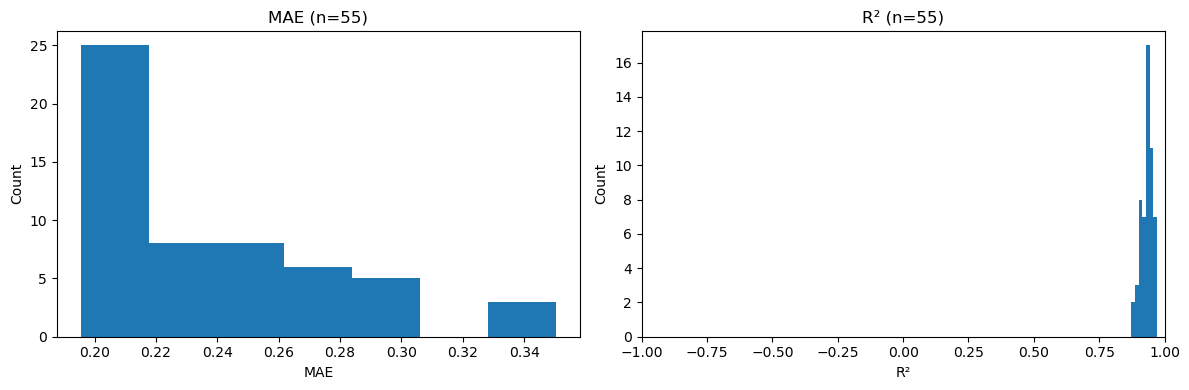

In [ ]:
#histograms for MAE and R²
# Safely extract numeric series
mae = pd.to_numeric(summary_df.get('mae', pd.Series(dtype=float)), errors='coerce').dropna()
r2  = pd.to_numeric(summary_df.get('r2',  pd.Series(dtype=float)), errors='coerce').dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# MAE histogram
if len(mae):
    axes[0].hist(mae, bins='auto')
    axes[0].set_title(f"MAE (n={len(mae)})")
    axes[0].set_xlabel("MAE")
    axes[0].set_ylabel("Count")
else:
    axes[0].text(0.5, 0.5, "No MAE data", ha="center", va="center")
    axes[0].axis("off")

# R² histogram
if len(r2):
    axes[1].hist(r2, bins='auto')
    axes[1].set_title(f"R² (n={len(r2)})")
    axes[1].set_xlabel("R²")
    axes[1].set_ylabel("Count")
    axes[1].set_xlim(-1, 1)
else:
    axes[1].text(0.5, 0.5, "No R² data", ha="center", va="center")
    axes[1].axis("off")

plt.tight_layout()
plt.show()